In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

from bioio import BioImage

# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")
channels = ["PRRT", "A1", "PSD", "RIM"]
data_path = Path(
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/Experiment-358.czi"
)
image = BioImage(data_path)
data = image.xarray_dask_data.assign_coords({"C": channels})

In [ ]:
import napari

v = napari.Viewer()
v.add_image(image.data, channel_axis=1, name=channels)

# 2. Drift correction

In [3]:
from prrt_clustering import correct_z_drift

shift, stabilized = correct_z_drift(data)

In [ ]:
import matplotlib.pyplot as plt

plt.plot(shift.reset_index()["Z"], shift["DX [um]"])
plt.plot(shift.reset_index()["Z"], shift["DY [um]"])
plt.legend(["X", "Y"])
plt.xlabel("Z [um]")
plt.ylabel("shift [um]")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

n = 500
a = data[0, 2, :, :n, :n].max(axis=1)
b = stabilized[0, 2, :, :n, :n].max(axis=1)
plt.subplot(311)
a.plot(add_colorbar=False, cmap="gray")
plt.subplot(312)
b.plot(add_colorbar=False, cmap="gray")
plt.subplot(313)
plt.imshow(np.stack([a, b, a], axis=2), aspect=4)
plt.suptitle("Z drift correction")
plt.tight_layout()


In [ ]:
# import napari
# v = napari.Viewer()
# v.add_image(image.data, channel_axis=1)
# v.add_image(stabilized.data[0,0,:,:100,:100], channel_axis=1)

## 3. Spot detection

- Detect spots in all channels

(<Figure size 2000x2000 with 4 Axes>,
 {'A1': <Axes: title={'center': 'A1'}>,
  'PRRT': <Axes: title={'center': 'PRRT'}>,
  'PSD': <Axes: title={'center': 'PSD'}>,
  'RIM': <Axes: title={'center': 'RIM'}>})

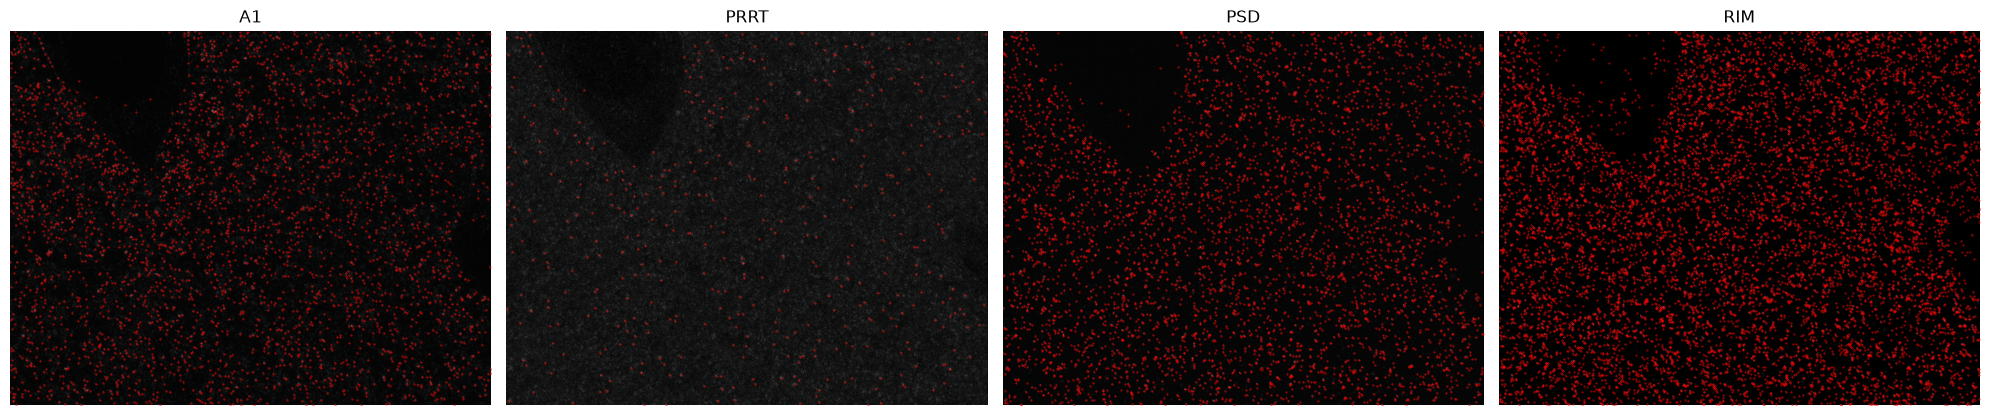

In [259]:
import matplotlib.pyplot as plt
import numpy as np

from prrt_clustering import detect_puncta, plot_data, plot_points

tmp = stabilized[0]#, :, :, 250:500, 800:1000]
parameters = {
    "PRRT": {"scale_um": 0.4, "specificity": 6},
    "A1": {"scale_um": 0.3, "specificity": 6},
    "PSD": {"scale_um": 0.1, "specificity": 8},
    "RIM": {"scale_um": 0.1, "specificity": 6},
}

points = detect_puncta(tmp, parameters)

fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp, split=True, fig=fig)
plot_points(points, ms=1, split=True, axes_dict=axes)


In [ ]:
import napari

v = napari.Viewer(ndisplay=3)
# v.add_image(image.data, channel_axis=1)
vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
# v.add_image(tmp,scale=vx,translate=o, channel_axis=0,name=channels)
fcol = {"PRRT": "magenta", "A1": "red", "PSD": "green", "RIM": "yellow"}
for n, pts in points.groupby("C"):
    v.add_image(tmp.sel(C=n), scale=vx, translate=o, name=n, colormap=fcol[n])
    v.add_points(pts[["Z", "Y", "X"]], size=0.5, name=n, face_color=fcol[n])

## 3. Clustering of RIM and PSD channels
Cluster points to identify potential synapses.

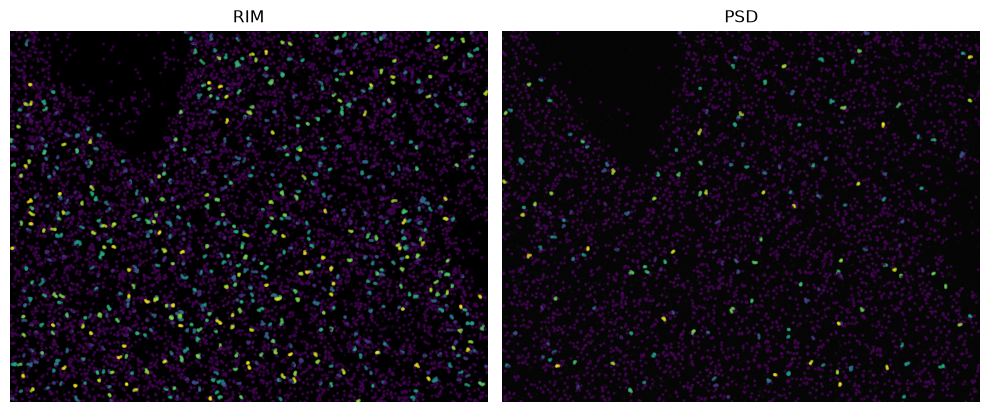

In [260]:
from prrt_clustering import cluster_dbscan

points, clusters = cluster_dbscan(points, eps=1, min_samples=3)

fig = plt.figure(figsize=(10, 10))
fig, axes = plot_data(tmp.sel(C=["RIM", "PSD"]), split=True, fig=fig)
for n, g in points[points["C"].isin(["RIM", "PSD"])].groupby("C"):
    axes[n].scatter(g["X"], g["Y"], c=g["cluster_id"], s=2,alpha=0.5)


## 4. Pre-post synpatic cluster association
Identify synapses as pair of cluster

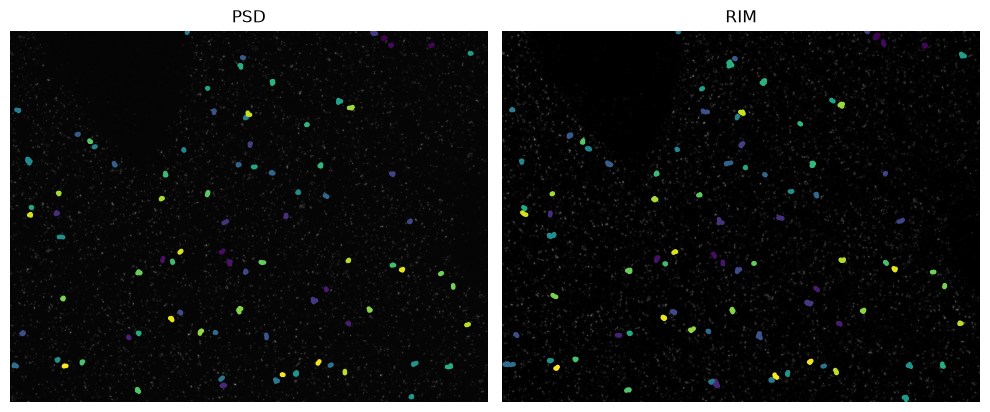

In [261]:
from prrt_clustering import pair_cluster

points, synapses = pair_cluster(points, ["PSD", "RIM"], distance=1)

fig = plt.figure(figsize=(10, 10))
fig, axes = plot_data(tmp.sel(C=["PSD", "RIM"]), split=True, fig=fig)
for n, g in points[points["synapse_id"] >= 0].groupby("C"):
    axes[n].scatter(g["X"], g["Y"], c=g["synapse_id"], s=5)


## 5. Identify pair of A1-PRRT

Identify pair of A1-PRRT puncta


In [263]:
from prrt_clustering import pair_puncta

points, pairs = pair_puncta(points, ["A1", "PRRT"], distance=0.5)

## 6. Synapse profiling

For each synapse, associate the puncate in all channel


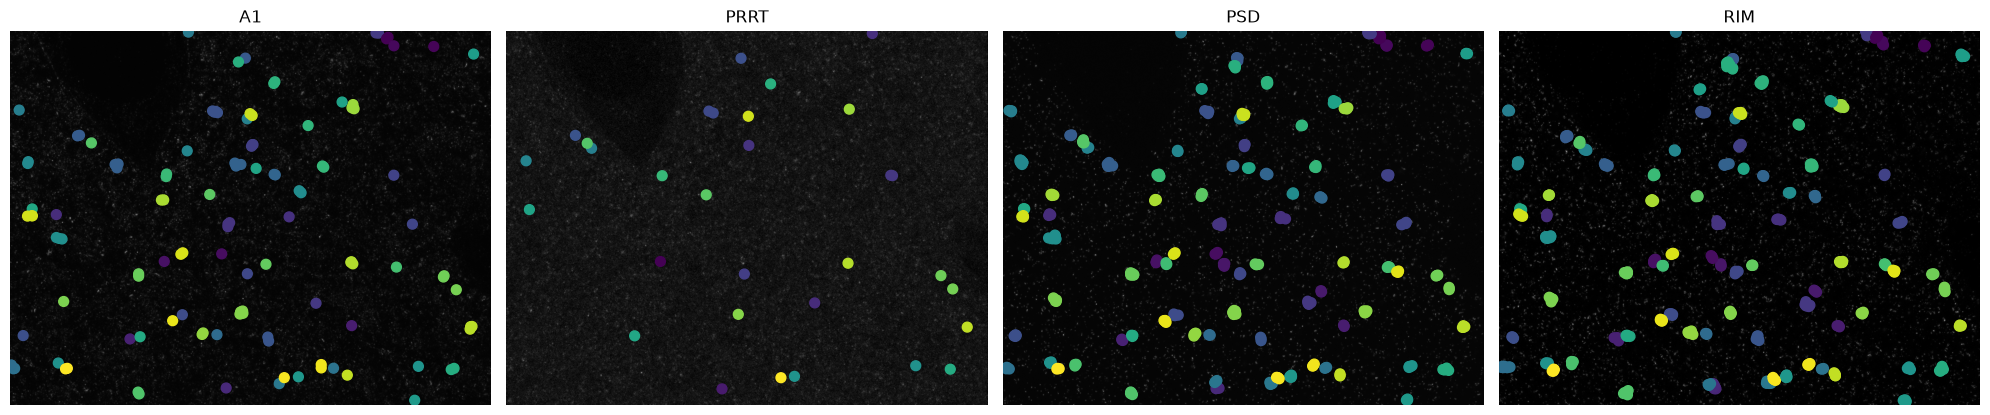

In [264]:
from prrt_clustering.clustering import associate_to_paired_cluster, compute_distances

points = associate_to_paired_cluster(points, 1)
points = compute_distances(points)

fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp, split=True, fig=fig)
for n, g in points.groupby("C"):
    axes[n].scatter(g["X"], g["Y"], c=g["synapse_id"], s=50)


Extract statistics

In [265]:
from prrt_clustering import global_stats, synapse_stats

gst = global_stats(points, 1, 2., 1)
sst = synapse_stats(points)

Make figure

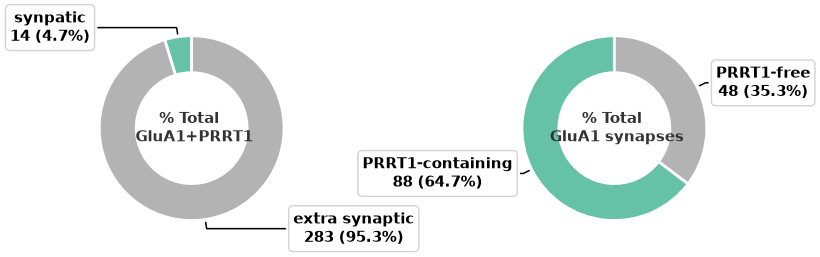

In [267]:
from prrt_clustering.plot import bagel_chart

# Compute for each synapse the number of synpase with PRRT vs the number of PRRT free synapse.
data1 = dict()
data1["synpatic"] = gst["Number of PRRT+GluA1 synpases"]
data1["extra synaptic"] = gst["Number of PRRT+GluA1 total"] - gst["Number of PRRT+GluA1 synpases"]

data2 = dict()
data2["PRRT1-containing"] = ( sst["Number of PRRT puncta"] >= 0).sum()
data2["PRRT1-free"] = ((sst["Number of PRRT puncta"] == 0)&(sst["Number of A1 puncta"] > 0)).sum()
fig,ax = plt.subplots(1,2,figsize=(10,3))
bagel_chart(data1,"% Total \n GluA1+PRRT1",ax=ax[0])
bagel_chart(data2,"% Total \n GluA1 synapses",ax=ax[1])


Text(0, 0.5, 'Number of detected of synaptic PRRT1')

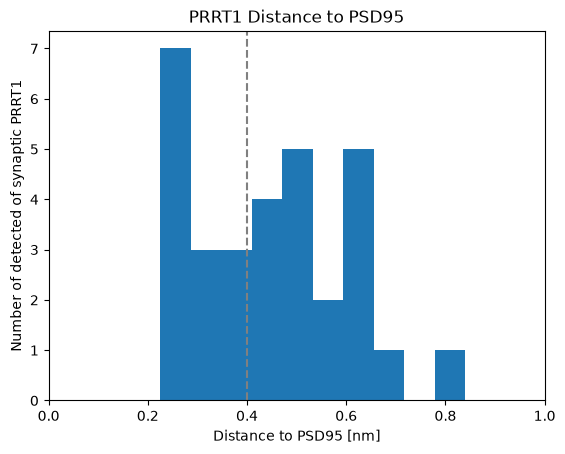

In [277]:
dist_prrt_psd = points[(points["C"]=="PRRT")&(points["synapse_id"]>=0)]["distance to PSD"]

plt.hist(dist_prrt_psd)
plt.axvline(x=0.4,color="gray",linestyle='--')
plt.xlim(0,1)
plt.title("PRRT1 Distance to PSD95")
plt.xlabel("Distance to PSD95 [nm]")
plt.ylabel("Number of detected of synaptic PRRT1")

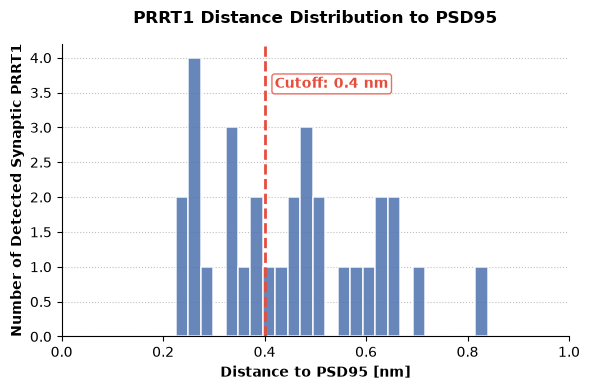

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


# Create figure with a clean, publication-friendly size
fig, ax = plt.subplots(figsize=(6, 4))

# 1. Styled histogram bars with nice colors, clear edges, and optimal binning
n, bins, patches = ax.hist(
    dist_prrt_psd,
    bins=25,
    color="#4c72b0",
    edgecolor="white",
    linewidth=1.2,
    alpha=0.85,
)

# 2. Emphasized threshold line
threshold = 0.4
ax.axvline(
    x=threshold,
    color="#e74c3c",
    linestyle="--",
    linewidth=2,
    label=f"Threshold ({threshold} μm)",
)

# 3. Add text annotation for the threshold line
ax.text(
    threshold + 0.02,
    ax.get_ylim()[1] * 0.85,
    f"Cutoff: {threshold} nm",
    color="#e74c3c",
    weight="bold",
    # fontsize=9,
    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#e74c3c", alpha=0.8),
)

# Axis limits and labels with clean typography
ax.set_xlim(0, 1)
ax.set_title(
    "PRRT1 Distance Distribution to PSD95", weight="bold", pad=15
)
ax.set_xlabel("Distance to PSD95 [nm]",  weight="semibold")
ax.set_ylabel(
    "Number of Detected Synaptic PRRT1",  weight="semibold"
)

# 4. Subtle background grid for easier reading of values
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle=":", alpha=0.5, color="gray")

# 5. Minimalist styling: remove top and right borders (spines)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()